In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
#warnings.simplefilter(action='ignore', category=np.VisibleDeprecationWarning)

## Testing Hypotheses

I flipped a coin 100 times. The result was Heads 35 times.

Null Hypothesis: The coin is fair - random chance is sufficient to explain this outcome.

Alternative Hypothesis (rejecting the Null Hypothesis): Random chance is *not* sufficient to explain this outcome.

# Step 1: Create Function for 100 Fair Coin Flips

In [ ]:
def coin_flip_100():
    
    num_heads = 0

    for i in np.arange(100):
        coin = make_array('heads', 'tails')
        flip = np.random.choice(coin)

        if flip == 'heads':
            num_heads = num_heads + 1
            
    return num_heads

In [7]:
coin_flip_100()

50

# Step 2: Iterate the experiment many times

## Bad Test Statistic 

Using the raw number of heads is a bad test statistic, since both big and small values favor the alternative hypothesis.

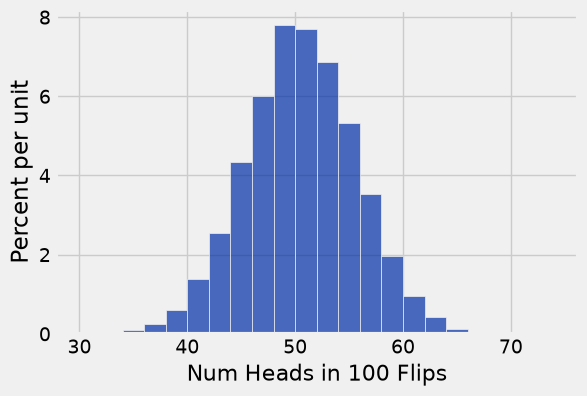

In [8]:
outcomes_array = make_array()

for i in np.arange(10000):
    experimental_outcome = coin_flip_100()
    outcomes_array = np.append(outcomes_array, experimental_outcome)

outcomes_tbl = Table().with_column('Num Heads in 100 Flips', outcomes_array)
outcomes_tbl.hist(bins = np.arange(30, 75, 2))

## Good Test Statistic

We can use "distance from expectation" as our test statistic.

Small (near 0) values favor the null hypothesis.

Big values favor the alternative hypothesis.

In [9]:
def coin_dist_from_expectation(num_flips):
    return abs(num_flips - 50)

In [10]:
coin_dist_from_expectation(40)

10

## Practice

Simulate the "distance from expectation" statistic 10,000 times and plot the results as a histogram.

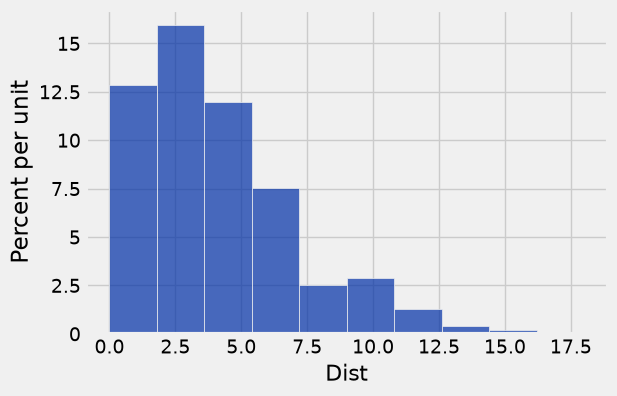

In [20]:
dist_outcomes = make_array()

for i in np.arange(10000):
    experiment_outcome = coin_flip_100()
    statistic = coin_dist_from_expectation(experiment_outcome)
    dist_outcomes = np.append(dist_outcomes, statistic)

outcomes_table = Table().with_column('Dist', dist_outcomes)
outcomes_table.hist('Dist')

## p-value ##

The p-value of a test is the chance, based on the model in the null hypothesis, that the test statistic will be equal to the observed value in the sample or even further in the direction that supports the alternative.

The np.count_nonzero function is useful for this calculation.

In [21]:
# Example: What percent of elements in arr are bigger than or equal to 5?
arr = make_array(1, 2, 3, 3, 4, 5, 5, 6, 6, 6, 7, 8, 9, 9)
num_bigger = np.count_nonzero(arr >= 5)
num_total = len(arr)
percent_bigger = num_bigger / num_total * 100
percent_bigger

64.285714285714292

# Practice

Suppose I flipped 40 heads out of 100.

What is the p-value of this experimental observation (40 heads out of 100)?


In [22]:
biggerthan10 = np.count_nonzero(dist_outcomes >= 10)
total = len(dist_outcomes)
percentbigger = biggerthan10/total * 100
percentbigger


5.5300000000000002

In [ ]:
#5.3% likely that the null hypothesis is correct

Conventional to say:

p-value less than 0.05 is "statistically significant" evidence for rejecting the null hypothesis.

p-value less than 0.01 is "highly statistically significant" evidence for rejecting the null hypothesis.